# Módulo 3: Perfilamiento Territorial de Cruces Críticos (PCA + K-Medias)

## 1. Contexto y Objetivo
Ante la baja predictibilidad del calendario (demostrada en el Módulo 2), este notebook aborda la dimensión espacial de la siniestralidad vial. Analizamos las **Top 200 intersecciones urbanas más frecuentes** para reducir su dimensionalidad mediante **PCA** y segmentarlas con **K-Medias** según su tipología de riesgo.

## 2. Variables de Perfilamiento por Intersección
- **Volumen total:** Conteo de siniestros registrados en la intersección.
- **Severidad:** Proporción de accidentes graves (con lesionados o fallecidos).
- **Composición vehicular:** Proporción de participación de motocicletas, vehículos de carga pesada y bicicletas.

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [20]:
df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')

C:\Users\santa\AppData\Local\Temp\ipykernel_16536\2175947294.py:1: DtypeWarning: Columns (0: codigo, 1: medio_reporte, 2: direccion_original, 3: direccion_norm) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')


In [21]:
# 1. Target binario y dirección canónica
df['grave'] = df['severidad'].isin(['Con lesionado', 'Con fallecido']).astype(int)

def canon(s):
    return ' CON '.join(sorted(p.strip() for p in str(s).split(' CON ')))
df['lugar'] = df['direccion_norm'].map(canon)

# 2. Subconjunto con direcciones válidas
w = df[(df['direccion_valida'] == True) & (df['anio'] <= 2022)].copy()
print('Años en w:', sorted(w['anio'].unique()))

# 3. Columnas de vehículos (nombres explícitos). Los NaN se dejan como NaN:
#    mean() y count() los ignoran, así "sin dato" no se confunde con "sin moto"
col_moto, col_carga, col_bici = 'veh_moto', 'veh_carga_pesada', 'veh_bicicleta'
for col in [col_moto, col_carga, col_bici]:
    w[col] = w[col].astype(float)

# 4. Top 200 cruces más frecuentes
top_200_lugares = w['lugar'].value_counts().head(200).index
df_top200 = w[w['lugar'].isin(top_200_lugares)].copy()

# 5. Perfil por cruce
perfil_cruces = (
    df_top200.groupby('lugar')
    .agg(
        volumen_total=('grave', 'size'),
        pct_graves=('grave', 'mean'),
        pct_motos=(col_moto, 'mean'),
        pct_carga_pesada=(col_carga, 'mean'),
        n_con_veh=(col_moto, 'count'),   # filas con dato de vehículos
    )
    .reset_index()
)

# Descartar cruces con pocos registros que tengan dato de vehículos
antes = len(perfil_cruces)
perfil_cruces = perfil_cruces[perfil_cruces['n_con_veh'] >= 15].reset_index(drop=True)
print(f'Cruces descartados por tener < 15 filas con dato de vehículos: {antes - len(perfil_cruces)} de {antes}')

# 6. Escalado
feat_cols = ['volumen_total', 'pct_graves', 'pct_motos', 'pct_carga_pesada']
X_raw = perfil_cruces[feat_cols]
X_scaled = StandardScaler().fit_transform(X_raw)

print(f'Cruces para clustering: {len(perfil_cruces)}')
perfil_cruces.head()

Años en w: [np.int64(2016), np.int64(2017), np.int64(2021), np.int64(2022)]
Cruces descartados por tener < 15 filas con dato de vehículos: 1 de 200
Cruces para clustering: 199


,lugar,volumen_total,pct_graves,pct_motos,pct_carga_pesada,n_con_veh
0,AVENIDA 2 CON CALLE 70,30,0.233333,0.250000,0.250000,20
1,AVENIDA 2N CON CALLE 25,35,0.200000,0.250000,0.312500,32
2,AVENIDA 2N CON CALLE 70,40,0.325000,0.277778,0.222222,36
3,AVENIDA 3 CON CALLE 70,35,0.371429,0.269231,0.307692,26
4,AVENIDA 3N CON CALLE 25,40,0.325000,0.343750,0.187500,32


In [22]:
# 1. Reducción a 2 componentes principales con PCA para visualización
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

perfil_cruces['pca_1'] = X_pca[:, 0]
perfil_cruces['pca_2'] = X_pca[:, 1]

var_explicada = pca.explained_variance_ratio_.sum()
print(f'Varianza explicada acumulada por PCA (2D): {var_explicada:.1%}')

# 2. Agrupamiento con K-Medias (k=3 clústeres)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
perfil_cruces['cluster'] = kmeans.fit_predict(X_scaled)

Varianza explicada acumulada por PCA (2D): 74.1%


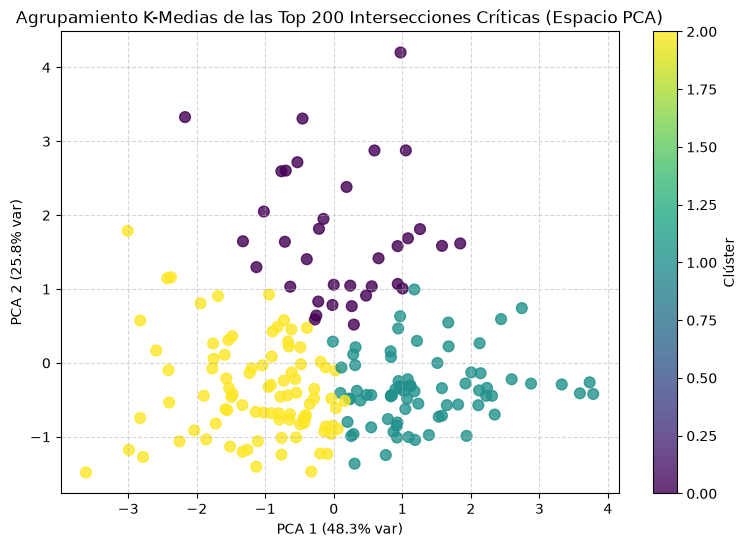

,volumen_total,pct_graves,pct_motos,pct_carga_pesada
cluster,,,,
0,103.685714,0.471009,0.457380,0.163884
1,39.689189,0.540666,0.518667,0.110986
2,49.655556,0.334075,0.324812,0.186460


In [23]:
# 1. Gráfica de dispersión en el espacio PCA
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    perfil_cruces['pca_1'],
    perfil_cruces['pca_2'],
    c=perfil_cruces['cluster'],
    cmap='viridis',
    s=60,
    alpha=0.8,
)
plt.title(
    'Agrupamiento K-Medias de las Top 200 Intersecciones Críticas (Espacio PCA)'
)
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]:.1%} var)')
plt.colorbar(scatter, label='Clúster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Caracterización promedio por clúster
resumen_clusters = perfil_cruces.groupby('cluster')[feat_cols].mean()
display(resumen_clusters)

In [24]:
print(perfil_cruces['cluster'].value_counts().sort_index().to_string(), '\n')

# 2. Cargas del PCA
print(pd.DataFrame(pca.components_.T, index=feat_cols, columns=['PCA1', 'PCA2']).round(2), '\n')

# 3. ¿Cuántos grupos hay? Silueta por k
for k in range(2, 7):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    print(f'k={k}: silueta={silhouette_score(X_scaled, lab):.3f}')

# 4. Estabilidad frente a la semilla (k=3)
base = perfil_cruces['cluster']
ari = [adjusted_rand_score(base, KMeans(n_clusters=3, random_state=s, n_init=1).fit_predict(X_scaled))
       for s in range(10)]
print(f'\nARI medio entre semillas: {np.mean(ari):.3f}')

# 5. ¿Persiste el perfil entre 2016-17 y 2021-22?
t = w[w['lugar'].isin(perfil_cruces['lugar'])].copy()
t['p'] = np.where(t['anio'] <= 2017, 'p1', 'p2')
pp = (t.groupby(['lugar', 'p'])
        .agg(n=('grave', 'size'), graves=('grave', 'mean'),
             n_veh=(col_moto, 'count'), motos=(col_moto, 'mean'))
        .unstack('p'))
ok = pp[(pp[('n', 'p1')] >= 10) & (pp[('n', 'p2')] >= 10)]
print(f'\nCruces con ≥10 siniestros en ambos períodos: {len(ok)} de {len(pp)}')
print('Spearman % graves  (2016-17 vs 2021-22):',
      round(spearmanr(ok[('graves', 'p1')], ok[('graves', 'p2')])[0], 2))
okv = ok[(ok[('n_veh', 'p1')] >= 10) & (ok[('n_veh', 'p2')] >= 10)]
print(f'Spearman % motos   (2016-17 vs 2021-22): '
      f"{round(spearmanr(okv[('motos', 'p1')], okv[('motos', 'p2')])[0], 2)} (n={len(okv)})")
top = ok[ok[('graves', 'p1')] >= ok[('graves', 'p1')].quantile(0.75)]
print(f"Cuartil más grave en 2016-17: {top[('graves', 'p1')].mean():.1%} -> "
      f"{top[('graves', 'p2')].mean():.1%} en 2021-22 (todos los cruces: {ok[('graves', 'p2')].mean():.1%})")

cluster
0    35
1    74
2    90 

                  PCA1  PCA2
volumen_total    -0.12  0.93
pct_graves        0.61  0.22
pct_motos         0.61  0.16
pct_carga_pesada -0.48  0.26 

k=2: silueta=0.275
k=3: silueta=0.288
k=4: silueta=0.268
k=5: silueta=0.244
k=6: silueta=0.249

ARI medio entre semillas: 0.702

Cruces con ≥10 siniestros en ambos períodos: 184 de 199
Spearman % graves  (2016-17 vs 2021-22): 0.54
Spearman % motos   (2016-17 vs 2021-22): 0.41 (n=171)
Cuartil más grave en 2016-17: 66.5% -> 48.9% en 2021-22 (todos los cruces: 39.0%)


In [25]:
perfil_cruces['graves'] = (perfil_cruces['volumen_total'] * perfil_cruces['pct_graves']).round().astype(int)

g = perfil_cruces.groupby('cluster').agg(cruces=('lugar', 'size'),
                                         graves_total=('graves', 'sum'),
                                         graves_por_cruce=('graves', 'mean'))
g['% de cruces'] = (g['cruces'] / g['cruces'].sum() * 100).round(1)
g['% de graves'] = (g['graves_total'] / g['graves_total'].sum() * 100).round(1)
display(g.round(1))

display(perfil_cruces.sort_values('graves', ascending=False)
        [['lugar', 'cluster', 'volumen_total', 'graves', 'pct_graves', 'pct_motos']].head(10).round(2))

,cruces,graves_total,graves_por_cruce,% de cruces,% de graves
cluster,,,,,
0,35,1700,48.6,17.6,35.4
1,74,1602,21.6,37.2,33.4
2,90,1495,16.6,45.2,31.2


,lugar,cluster,volumen_total,graves,pct_graves,pct_motos
181,CALLE 70 CON CARRERA 8,0,171,99,0.58,0.59
197,CARRERA 23 CON TRANSVERSAL 25,0,140,80,0.57,0.44
99,CALLE 34 CON CARRERA 1,0,131,75,0.57,0.57
161,CALLE 70 CON CARRERA 1,0,148,73,0.49,0.43
49,CALLE 16 CON CARRERA 100,0,137,61,0.45,0.35
108,CALLE 44 CON CARRERA 1,0,123,57,0.46,0.51
140,CALLE 5 CON CARRERA 94,0,94,57,0.61,0.52
138,CALLE 5 CON CARRERA 80,0,110,56,0.51,0.56
90,CALLE 25 CON CARRERA 98,0,170,55,0.32,0.20
41,CALLE 13 CON DIAGONAL 23,0,143,55,0.38,0.42


### Concentración de siniestros graves en los cruces perfilados (dentro de la muestra)

| Clúster | Cruces | % de cruces | Graves | % de graves | Graves por cruce |
|---|---|---|---|---|---|
| 0 | 35 | 17.6% | 1,700 | 35.4% | 48.6 |
| 1 | 74 | 37.2% | 1,602 | 33.4% | 21.6 |
| 2 | 90 | 45.2% | 1,495 | 31.2% | 16.6 |

- Los 199 cruces (1.3% de los 14,969 lugares con siniestros) reúnen 4,797 graves: el 24.8% de los 19,347 graves con dirección válida en 2016-2022. Es una cifra descriptiva: el Top 200 se eligió con los mismos datos.
- El clúster 0 concentra el 35.4% de los graves con el 17.6% de los cruces, sobre todo porque se define por mayor número de siniestros; su severidad (47.1%) está solo ligeramente por encima del promedio del conjunto (43.5%).
- Los 10 cruces con más graves suman 668 (13.9% de los de la lista y 3.5% de todos los graves con dirección). Seis de ellos comparten calle (Carrera 1, Calle 70 y Calle 5), lo que sugiere analizar corredores y no solo esquinas aisladas.
- La evidencia de que la concentración persiste en el tiempo está en la sección 5 (fuera de muestra).

In [26]:
print(f"Graves en estos {len(perfil_cruces)} cruces: {perfil_cruces['graves'].sum():,} "
      f"de {int(w['grave'].sum()):,} graves con dirección válida "
      f"({perfil_cruces['graves'].sum() / w['grave'].sum():.1%})")

Graves en estos 199 cruces: 4,797 de 19,347 graves con dirección válida (24.8%)


In [27]:
chk = (df.groupby('anio')
         .agg(total=('grave', 'size'), con_dir_valida=('direccion_valida', 'sum')))
chk['pct_dir_valida'] = (chk['con_dir_valida'] / chk['total'] * 100).round(1)
chk['filas_en_w'] = w.groupby('anio').size()
chk['graves_en_w'] = w.groupby('anio')['grave'].sum()
chk['pct_grave_en_w'] = (w.groupby('anio')['grave'].mean() * 100).round(1)
display(chk)

,total,con_dir_valida,pct_dir_valida,filas_en_w,graves_en_w,pct_grave_en_w
anio,,,,,,
2016,16513,15729,95.3,15729.0,7995.0,50.8
2017,17016,10517,61.8,10517.0,4703.0,44.7
2018,23354,0,0.0,NaN,NaN,NaN
2019,23508,0,0.0,NaN,NaN,NaN
2020,13996,0,0.0,NaN,NaN,NaN
2021,11650,7850,67.4,7850.0,2758.0,35.1
2022,9979,9252,92.7,9252.0,3891.0,42.1
2023,4916,4337,88.2,NaN,NaN,NaN
2024,3957,3761,95.0,NaN,NaN,NaN


In [28]:
w_all = df[df['direccion_valida'] == True].copy()      # incluye 2023-24
train = w_all[(w_all['anio'] <= 2022) & (w_all['grave'] == 1)]
test = w_all[(w_all['anio'] >= 2023) & (w_all['grave'] == 1)]
n_lug = w_all['lugar'].nunique()

print(f'Graves de 2023-24 con dirección válida: {len(test):,}')
for N in (50, 100, 200):
    top = set(train['lugar'].value_counts().head(N).index)
    top_o = set(test['lugar'].value_counts().head(N).index)
    print(f"N={N}: captura {test['lugar'].isin(top).mean():.1%} "
          f"(azar ≈ {N/n_lug:.1%}, techo ≈ {test['lugar'].isin(top_o).mean():.1%}) "
          f"| solape de listas: {len(top & top_o)}/{N}")

Graves de 2023-24 con dirección válida: 7,248
N=50: captura 5.3% (azar ≈ 0.3%, techo ≈ 6.7%) | solape de listas: 29/50
N=100: captura 7.5% (azar ≈ 0.5%, techo ≈ 10.6%) | solape de listas: 47/100
N=200: captura 11.3% (azar ≈ 1.0%, techo ≈ 16.4%) | solape de listas: 89/200


## Conclusiones del Módulo 3: Perfilamiento Territorial de Intersecciones Críticas

### 1. Construcción del perfil
Se perfilaron 199 cruces (de los 200 más frecuentes con dirección válida en 2016-17 y 2021-22; los años 2018-2020 no tienen direcciones válidas y 2023-24 se reservaron para una prueba fuera de muestra). Se descartó 1 cruce por tener menos de 15 siniestros con dato de vehículos. Los porcentajes de vehículos se calculan solo con siniestros que tienen dato de vehículos: un registro sin dato no se cuenta como "sin moto". Se excluyó la bicicleta del clustering porque casi no aparece (menos del 1% en promedio). Variables finales: volumen, % graves, % motos, % carga pesada.

### 2. PCA (74.1% de varianza con 2 componentes)
- **PC1** (% graves 0.61, % motos 0.61, % carga pesada −0.48): contrapone cruces con muchas motos y alta severidad a cruces con más carga pesada.
- **PC2** (volumen 0.93): corresponde casi por completo al número de siniestros registrados. No mide tráfico ni congestión.

### 3. K-Medias (k = 3): segmentación descriptiva
La silueta es máxima en k=3 (0.288) pero baja en términos absolutos (0.24-0.29 para k=2 a 6): los cruces forman más un continuo que grupos separados. La estabilidad frente a la inicialización es moderada (ARI medio 0.70).

| Clúster | Cruces | Volumen | % graves | % motos | % carga pesada |
|---|---|---|---|---|---|
| 0 | 35 | 103.7 | 47.1% | 45.7% | 16.4% |
| 1 | 74 | 39.7 | 54.1% | 51.9% | 11.1% |
| 2 | 90 | 49.7 | 33.4% | 32.5% | 18.6% |

- **Clúster 0:** mucho mayor número de siniestros, con severidad ligeramente por encima del promedio de los cruces (~43.5%).
- **Clúster 1:** mayor severidad y mayor participación de motos.
- **Clúster 2:** menor severidad y mayor participación de carga pesada.
La participación de motos indica que hay una moto involucrada; no identifica quién resultó herido. Severidad y motos se mueven juntas (como en el Módulo 1), por lo que el clúster 1 es un solo hallazgo, no dos.

### 4. ¿Persiste el perfil en el tiempo? (2016-17 vs 2021-22, 184 cruces con ≥10 siniestros en ambos períodos)
- Correlación de Spearman: % graves 0.54; % motos 0.41 (n=171).
- Los cruces del cuartil más grave en 2016-17 pasan de 66.5% a 48.9% de graves en 2021-22 (promedio de ese período: 39.0%). Conservan parte de la ventaja, pero regresan con fuerza hacia el promedio.

### 5. ¿Persiste la concentración de siniestros graves? (fuera de muestra)
Se eligió una lista de los N cruces con más graves en un período y se midió qué parte de los graves con dirección válida de un período posterior cae en ella.

| Prueba | N=50 | N=100 | N=200 | Techo (N=200) | Solape (N=200) |
|---|---|---|---|---|---|
| Lista 2016-17 → graves 2021-22 | 10.6% | 16.3% | 24.0% | 29.7% | 118/200 |
| Lista 2016-22 → graves 2023-24 | 5.3% | 7.5% | 11.3% | 16.4% | 89/200 |

- Con N=200 (≈1% de los lugares), la lista captura entre 11% y 24% de los graves posteriores, unas 11 a 18 veces lo esperable por azar (≈1.0-1.3%). Más del 75% de los graves ocurre fuera de la lista.
- La captura baja a la mitad en 2023-24, sobre todo porque en ese período los graves están más dispersos (el techo baja de 29.7% a 16.4%); la causa no se ha determinado.
- El "techo" es la lista ideal construida con el propio período evaluado, por lo que es optimista.

### 6. Implicaciones
- La **frecuencia histórica** es el criterio principal para priorizar cruces: señala los lugares con más graves a futuro, aunque cubre una parte moderada del total.
- El perfil de severidad y de participación de motos sirve para **ordenar dentro** de esa lista, sabiendo que parte del valor observado es ruido que se corrige hacia el promedio.
- Posibles líneas de intervención (a evaluar; los datos no permiten medir su efecto): fiscalización de motocicletas en cruces con alto % de motos y graves.

### Limitaciones
- Solo siniestros con dirección válida (aprox. 37% de los registros 2016-2022), y solo en 2016-17 y 2021-22 para el perfilamiento.
- 2024 está incompleto; en 2023-24 los "Solo daños" casi desaparecen del registro, por lo que la evaluación usa solo graves.
- La persistencia se evaluó con dos pares de períodos; no se evaluó si la pertenencia a un clúster se mantiene.
- No se mide tráfico, velocidad ni infraestructura.